# Assignment 3 — Task 4: Clinical review figure

Clean the 10,000-record vital-sign file with an explicit audit trail, then build one reproducible 2×2 figure. Every exclusion is recorded; the figure uses explicit parameters, units, a fixed correlation scale, and 300 dpi output.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from vizlib import PALETTE, save_fig, style_defaults

DATA = Path("data")
style_defaults()
df = pd.read_csv(DATA / "vitals_10k.csv")
print(df.info())
display(df.describe().T)
display(df["ward"].value_counts())
print(df["admit_date"].head(20).tolist())
for column in ["heart_rate", "bmi", "spo2", "los_days"]:
    print(column, df[column].min(), df[column].max())
LOG = {"rows loaded": f"{len(df):,}"}

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   patient_id      10000 non-null  object 
 1   admit_date      10000 non-null  object 
 2   ward            10000 non-null  object 
 3   age             10000 non-null  int64  
 4   sex             10000 non-null  object 
 5   systolic        10000 non-null  int64  
 6   diastolic       10000 non-null  int64  
 7   map_mmhg        10000 non-null  float64
 8   heart_rate      10000 non-null  int64  
 9   spo2            10000 non-null  int64  
 10  bmi             10000 non-null  float64
 11  chol_mmol_l     10000 non-null  float64
 12  glucose_mmol_l  10000 non-null  float64
 13  los_days        10000 non-null  float64
 14  readmitted_30d  10000 non-null  int64  
 15  risk_score      10000 non-null  float64
dtypes: float64(6), int64(6), object(4)
memory usage: 1.2+ MB
None


,count,mean,std,min,25%,50%,75%,max
age,10000.0,58.113800,16.639728,18.0,47.000000,58.0000,69.0000,97.00
systolic,10000.0,137.656700,22.597192,92.0,119.000000,128.0000,160.0000,199.00
diastolic,10000.0,79.628200,13.134109,45.0,69.000000,78.0000,90.0000,125.00
map_mmhg,10000.0,98.970690,15.830095,65.3,85.700000,94.3000,113.7000,149.70
heart_rate,10000.0,78.833100,20.557021,0.0,69.000000,78.0000,87.0000,415.00
spo2,10000.0,96.724000,2.239671,81.0,96.000000,97.0000,98.0000,100.00
bmi,10000.0,66.177040,190.996849,0.0,24.000000,27.6000,31.2000,999.00
chol_mmol_l,10000.0,4.823818,1.010410,2.1,4.140000,4.8200,5.5100,8.79
glucose_mmol_l,10000.0,6.550060,1.145823,5.1,5.700000,6.3000,7.1000,13.90
los_days,10000.0,2.309091,8.923347,0.0,0.610000,1.3800,2.5700,273.65


ward
General Medicine    1356
general medicine    1353
Gen Medicine        1309
CARDIOLOGY           914
cardio               886
Cardiology           882
Day Surgery          749
Day-Surgery          730
Intensive Care       486
ICU                  480
 I.C.U               442
icu                  413
Name: count, dtype: int64

['2026-01-19', '08-Mar-2026', '2026-02-26', '27/02/2026', '09/01/2026', '01-Apr-2026', '17-Apr-2026', '24-Mar-2026', '14-Apr-2026', '02-Jan-2026', '10/03/2026', '10/02/2026', '12-Apr-2026', '29/03/2026', '17-Apr-2026', '12/02/2026', '2026-03-28', '2026-02-03', '11-Apr-2026', '08/01/2026']
heart_rate 0 415
bmi 0.0 999.0
spo2 81 100
los_days 0.0 273.65


In [2]:
# Explicitly standardise ward spellings before grouping.
ward_map = {
    "general medicine": "General Medicine", "gen medicine": "General Medicine",
    "cardiology": "Cardiology", "cardio": "Cardiology",
    "day surgery": "Day Surgery", "day-surgery": "Day Surgery",
    "intensive care": "Intensive Care", "icu": "Intensive Care", "i.c.u": "Intensive Care",
}
raw_ward = df["ward"].astype(str).str.strip().str.lower()
df["ward_clean"] = raw_ward.map(ward_map)
if df["ward_clean"].isna().any():
    raise ValueError("Unmapped ward values: " + str(raw_ward[df["ward_clean"].isna()].unique()))
LOG["ward spellings conformed"] = f"{raw_ward.nunique()} spellings -> {df['ward_clean'].nunique()} wards"

def parse_dates(series):
    parsed = pd.to_datetime(series, format="%Y-%m-%d", errors="coerce")
    parsed = parsed.fillna(pd.to_datetime(series, format="%d-%b-%Y", errors="coerce"))
    parsed = parsed.fillna(pd.to_datetime(series, format="%d/%m/%Y", errors="coerce"))
    parsed = parsed.fillna(pd.to_datetime(series, format="%m/%d/%Y", errors="coerce"))
    if parsed.isna().any():
        raise ValueError("Unparsed admission dates remain")
    return parsed

df["admit_dt"] = parse_dates(df["admit_date"])
LOG["dates parsed"] = "ISO, day-month-name, day/month/year, and month/day/year parsed explicitly"

bmi_sentinel = df["bmi"] > 100
bmi_before = df.loc[~bmi_sentinel, "bmi"].mean()
df.loc[bmi_sentinel, "bmi"] = np.nan
LOG["bmi sentinels removed"] = f"{bmi_sentinel.sum()} values > 100 replaced with NaN; mean of valid BMI = {bmi_before:.2f}"

hr_fault = df["heart_rate"] > 250
hr_before = df["heart_rate"].mean()
df.loc[hr_fault, "heart_rate"] = np.nan
hr_after = df["heart_rate"].mean()
LOG["heart-rate device faults removed"] = f"{hr_fault.sum()} readings > 250 bpm; mean {hr_before:.2f} -> {hr_after:.2f} bpm"

LOG["derived column excluded"] = "map_mmhg excluded from the heatmap because it is computed from systolic and diastolic"
print("\n".join(f"{key}: {value}" for key, value in LOG.items()))


rows loaded: 10,000
ward spellings conformed: 9 spellings -> 4 wards
dates parsed: ISO, day-month-name, day/month/year, and month/day/year parsed explicitly
bmi sentinels removed: 402 values > 100 replaced with NaN; mean of valid BMI = 27.11
heart-rate device faults removed: 29 readings > 250 bpm; mean 78.83 -> 77.98 bpm
derived column excluded: map_mmhg excluded from the heatmap because it is computed from systolic and diastolic


Wrote partD_figure.png


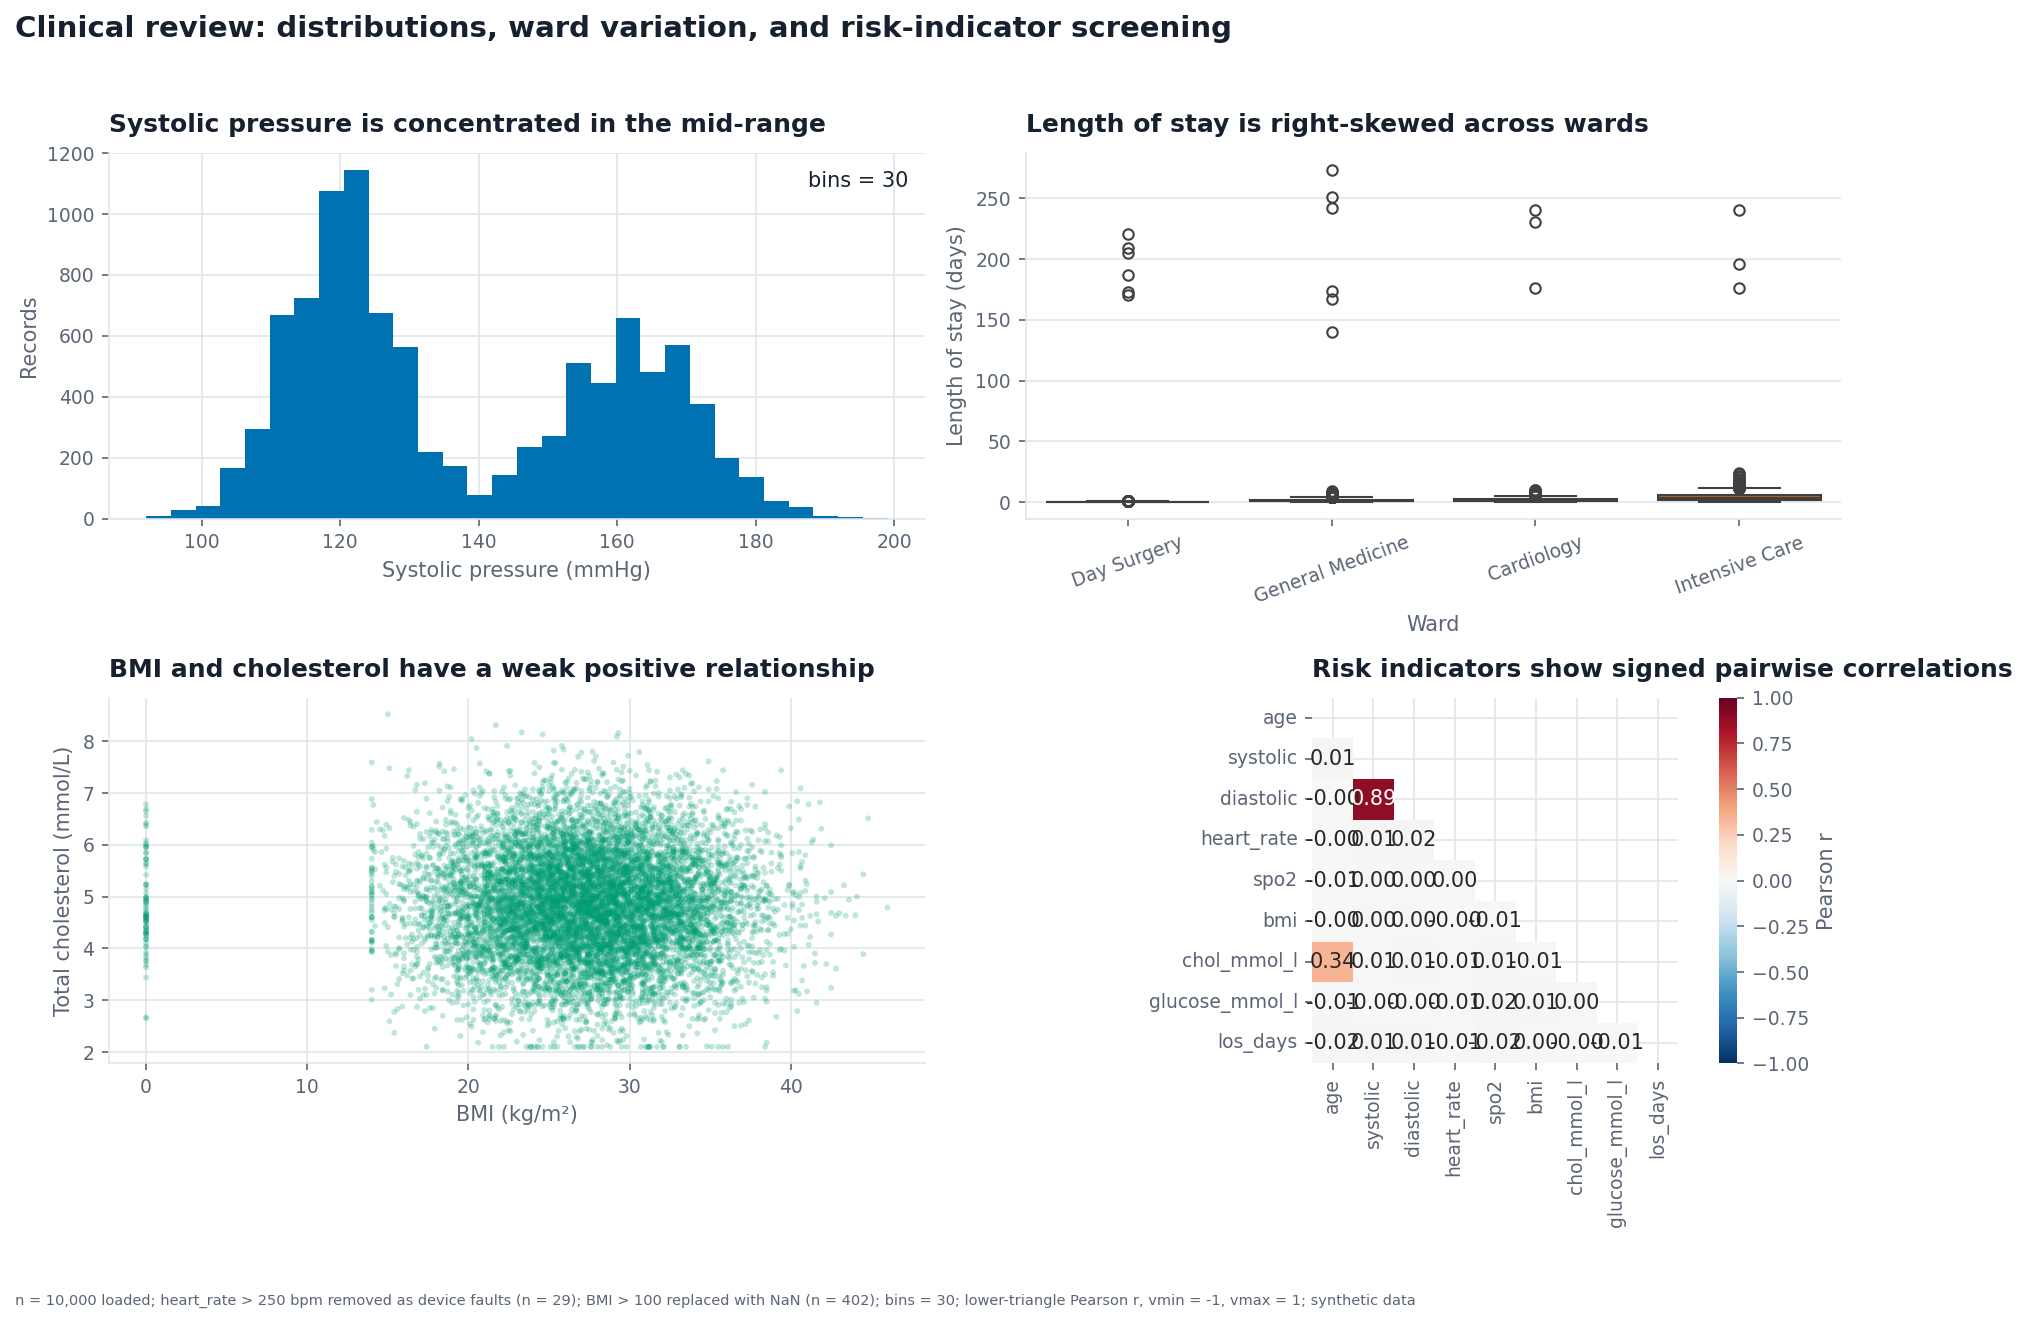

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12.6, 8.4))

# Panel 1: explicit bin count selected after checking candidate resolutions.
axes[0, 0].hist(df["systolic"].dropna(), bins=30, color=PALETTE["series"][0])
axes[0, 0].set(title="Systolic pressure is concentrated in the mid-range",
               xlabel="Systolic pressure (mmHg)", ylabel="Records")
axes[0, 0].text(.98, .95, "bins = 30", transform=axes[0, 0].transAxes, ha="right", va="top")

# Panel 2: sort wards by their median and show the skew explicitly.
ward_order = df.groupby("ward_clean")["los_days"].median().sort_values().index
sns.boxplot(data=df, x="ward_clean", y="los_days", order=ward_order,
            color=PALETTE["series"][1], ax=axes[0, 1])
axes[0, 1].set(title="Length of stay is right-skewed across wards",
               xlabel="Ward", ylabel="Length of stay (days)")
axes[0, 1].tick_params(axis="x", rotation=20)

# Panel 3: pair selected from the correlation screen.
axes[1, 0].scatter(df["bmi"], df["chol_mmol_l"], s=8, alpha=.25,
                   color=PALETTE["series"][2], edgecolors="none")
axes[1, 0].set(title="BMI and cholesterol have a weak positive relationship",
               xlabel="BMI (kg/m²)", ylabel="Total cholesterol (mmol/L)")

# Panel 4: signed, fixed-scale, lower-triangle heatmap; derived MAP omitted.
heatmap_cols = ["age", "systolic", "diastolic", "heart_rate", "spo2", "bmi",
                "chol_mmol_l", "glucose_mmol_l", "los_days"]
matrix = df[heatmap_cols].corr()
mask = np.triu(np.ones_like(matrix, dtype=bool))
sns.heatmap(matrix, mask=mask, cmap=PALETTE["diverging"], vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", square=True, ax=axes[1, 1], cbar_kws={"label": "Pearson r"})
axes[1, 1].set(title="Risk indicators show signed pairwise correlations")

fig.suptitle("Clinical review: distributions, ward variation, and risk-indicator screening",
             x=.01, ha="left", fontsize=14, fontweight="bold")
for axis in axes.flat:
    axis.spines["top"].set_visible(False)
    axis.spines["right"].set_visible(False)
fig.tight_layout(rect=[0, 0, 1, .96])
note = ("n = 10,000 loaded; heart_rate > 250 bpm removed as device faults "
        f"(n = {hr_fault.sum()}); BMI > 100 replaced with NaN (n = {bmi_sentinel.sum()}); "
        "bins = 30; lower-triangle Pearson r, vmin = -1, vmax = 1; synthetic data")
output = save_fig(fig, "partD_figure.png", note)
print("Wrote", output)
plt.show()

### Part D audit

- **Panel 1:** distribution of systolic pressure; fixed 30 bins make the resolution reproducible.
- **Panel 2:** ward comparison; median ordering makes the right-skewed length-of-stay differences readable.
- **Panel 3:** the scatter is a screening view, not a causal result; alpha = 0.25 prevents 10,000 records becoming an opaque blob.
- **Panel 4:** the lower triangle removes duplication, while `RdBu_r` and −1 to +1 preserve the sign and comparable magnitude of correlations.
- **Exclusions:** device-fault heart rates are removed explicitly; BMI sentinels become missing values rather than plausible measurements. The source note carries the rules and counts.

### Submission checklist

- Run the inspection cell before plotting.
- Confirm the printed exclusion counts and means are included in the source note.
- Confirm `partD_figure.png` is saved before `plt.show()`.
- Do not use `showfliers=False` to hide device faults silently.